<a href="https://colab.research.google.com/github/ascot119-rgb/Alex-s-Projects/blob/main/Image_Classification_Algorithm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Standard MLP Networks

100%|██████████| 170M/170M [00:18<00:00, 9.02MB/s]


Time: 304.348915717 Seconds
Trainable Parameters: 820,874
Training Loss: 1.0938163
Training Accuracy 0.6156200170516968
Validation Accuracy 0.5080000162124634
Validation Precision 0.5449892425692368
Validation Recall 0.508


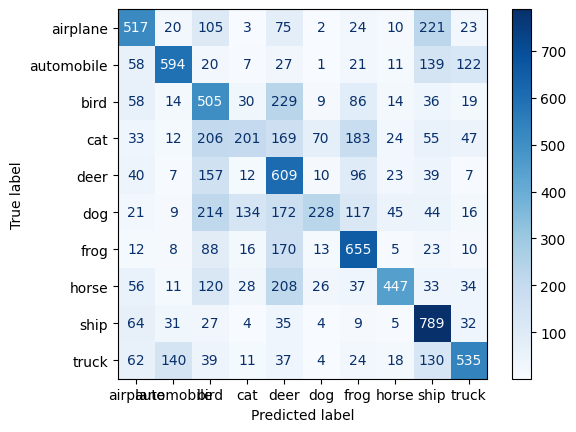

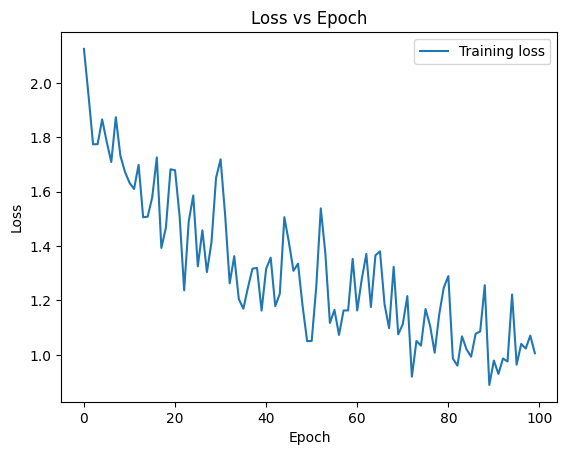

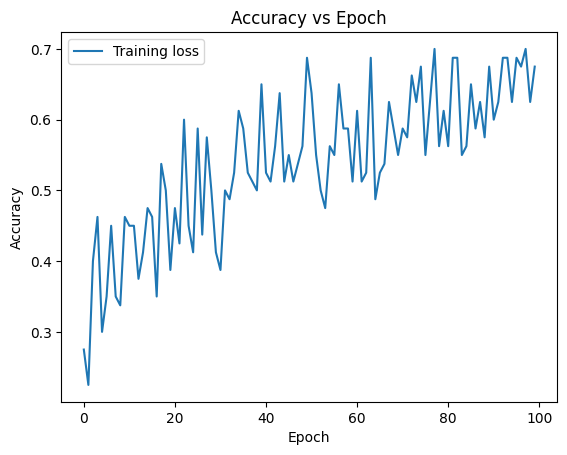

  Epoch    Accuracy      Loss
-------  ----------  --------
      0      0.275   2.12455
      1      0.225   1.95452
      2      0.4     1.77406
      3      0.4625  1.77425
      4      0.3     1.86567
      5      0.35    1.78297
      6      0.45    1.70906
      7      0.35    1.87367
      8      0.3375  1.73186
      9      0.4625  1.67298
     10      0.45    1.63297
     11      0.45    1.60977
     12      0.375   1.6987
     13      0.4125  1.50567
     14      0.475   1.50813
     15      0.4625  1.58017
     16      0.35    1.72586
     17      0.5375  1.3932
     18      0.5     1.46843
     19      0.3875  1.68213
     20      0.475   1.67881
     21      0.425   1.5104
     22      0.6     1.23739
     23      0.45    1.4901
     24      0.4125  1.58603
     25      0.5875  1.32546
     26      0.4375  1.45777
     27      0.575   1.30451
     28      0.5     1.41353
     29      0.4125  1.65023
     30      0.3875  1.71898
     31      0.5     1.51345
     32      0.4

In [1]:
import sys
import sympy
import sympy.logic
import sympy.logic.boolalg
# Forcefully bind the module into sympy namespace to bypass lazy loading issues
setattr(sympy, 'logic', sys.modules['sympy.logic'])
setattr(sympy, 'core', sys.modules['sympy.core'])

from torch.nn.modules.activation import LogSoftmax
import torch as pt
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import torch.nn as nn
from sklearn.metrics import ConfusionMatrixDisplay
import torchvision
import torchvision.transforms as transforms
from torchvision import datasets
import time
from sklearn.metrics import precision_score, recall_score
from tabulate import tabulate

cifar10 = torchvision.datasets.CIFAR10(root='./data', download=True)
cifar10_val = torchvision.datasets.CIFAR10(root='./data', train=False, download=True)


cifar_i = []
cifar_i_val = []
labels = []
labels_val = []
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


def getaccuracy(predict, y):
  c = 0
  for i in range(len(predict)):
    if abs(predict[i]-y[i]) <= 0.5:
      c += 1
  return c/len(predict)
def getf1(precision, recall):
  return 2*precision*recall/(precision+recall)

for i in range(len(cifar10)):
  img = pt.from_numpy(cifar10.data[i])
  img = img.permute(2,0,1)
  cifar_i.append(img)
  labels.append(cifar10.targets[i])

for i in range(len(cifar10_val)):
  img = pt.from_numpy(cifar10_val.data[i])
  img = img.permute(2,0,1)
  cifar_i_val.append(img)
  labels_val.append(cifar10_val.targets[i])


labels_orig = pt.tensor(labels.copy())

def softmax(x):
  return pt.exp(x) /pt.exp(x).sum()

cifar_i = pt.from_numpy(np.array(cifar_i)).to(pt.float32)/255
cifar_i_val = pt.from_numpy(np.array(cifar_i_val)).to(pt.float32)/255

cifar = pt.utils.data.TensorDataset(cifar_i, pt.from_numpy(np.array(labels)).to(pt.long))
cifar_val = pt.utils.data.TensorDataset(cifar_i_val, pt.from_numpy(np.array(labels_val)).to(pt.long))

train_loader = pt.utils.data.DataLoader(cifar, batch_size=128, shuffle=True)

model = nn.Sequential(
    nn.Linear(3072, 256),
    nn.ReLU(),
    nn.Linear(256, 128),
    nn.ReLU(),
    nn.Linear(128, 10),
    nn.LogSoftmax(dim=1)
)
loss_fn = nn.NLLLoss()
optimizer = pt.optim.SGD(model.parameters(), lr=0.01)
n_epochs = 100

start_time = time.perf_counter()
accuracy_over_time = []
loss_over_time = []

for epoch in range(n_epochs):
  for imgs, labels in train_loader:
    batch_size = imgs.shape[0]
    outputs = model(imgs.view(batch_size, -1))
    loss = loss_fn(outputs, labels)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
  loss_over_time.append(loss.detach().tolist())
  accuracy_over_time.append(getaccuracy(pt.argmax(outputs, dim=1), labels))

print("Time: " + str(time.perf_counter() - start_time) + " Seconds")

pred_val = model(cifar_i_val.view(cifar_i_val.shape[0], -1))
pred_val = pt.argmax(pred_val, dim=1)

pred_train = model(cifar_i.view(cifar_i.shape[0], -1))

disp = ConfusionMatrixDisplay.from_predictions(
    np.round(labels_val),
    pred_val.detach().numpy(),
    display_labels=class_names,
    cmap=plt.cm.Blues,
    normalize=None,
)

trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable Parameters: {trainable_params:,}")

print("Training Loss:", loss_fn(pred_train, labels_orig).detach().numpy())
pred_train = pt.argmax(pred_train, dim=1)
print("Training Accuracy", (pred_train == labels_orig).float().mean().item())
print("Validation Accuracy", (pred_val == pt.tensor(labels_val)).float().mean().item())
print("Validation Precision", precision_score(labels_val, pred_val, average="macro"))
print("Validation Recall", recall_score(labels_val, pred_val, average="macro"))
plt.figure()
plt.plot(np.arange(len(loss_over_time)), loss_over_time, label="Training loss")
plt.title("Loss vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()
plt.figure()
plt.plot(np.arange(len(accuracy_over_time)), accuracy_over_time, label="Training loss")
plt.title("Accuracy vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()
tabledata = [np.arange(len(accuracy_over_time)).tolist(), accuracy_over_time, loss_over_time]
tabledata = np.transpose(np.array(tabledata)).tolist()
table = tabulate(tabledata, headers=["Epoch", "Accuracy", "Loss"])
print(table)

Time: 584.518694582 Seconds
Trainable Parameters: 1,707,274
Training Loss: 0.8857769
Training Accuracy 0.6897799968719482
Validation Accuracy 0.544700026512146
Validation Precision 0.558106572368034
Validation Recall 0.5447


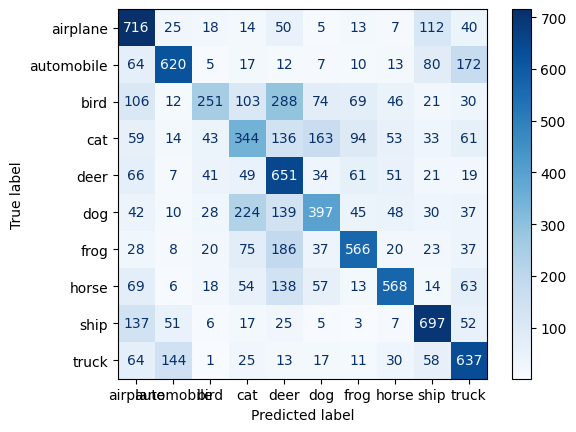

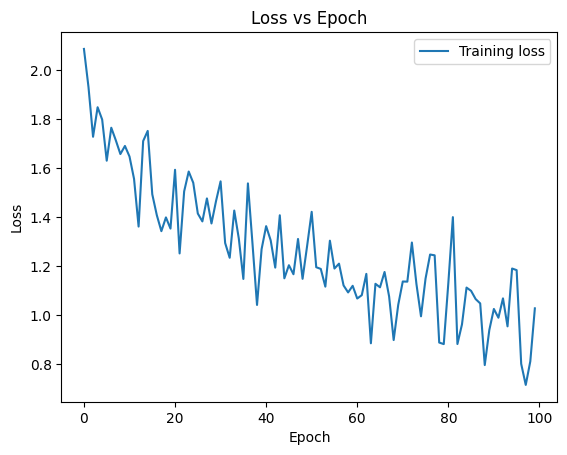

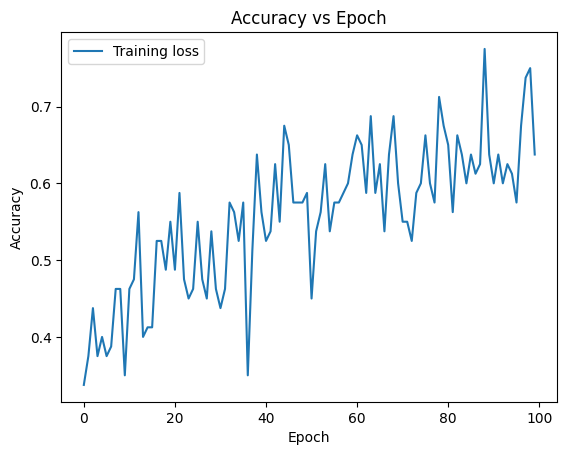

  Epoch    Accuracy      Loss
-------  ----------  --------
      0      0.3375  2.08708
      1      0.375   1.93074
      2      0.4375  1.7282
      3      0.375   1.84883
      4      0.4     1.79861
      5      0.375   1.63045
      6      0.3875  1.76513
      7      0.4625  1.7135
      8      0.4625  1.65755
      9      0.35    1.6907
     10      0.4625  1.64761
     11      0.475   1.5561
     12      0.5625  1.36132
     13      0.4     1.7107
     14      0.4125  1.75212
     15      0.4125  1.49322
     16      0.525   1.40774
     17      0.525   1.34255
     18      0.4875  1.39874
     19      0.55    1.35306
     20      0.4875  1.59332
     21      0.5875  1.25153
     22      0.475   1.50504
     23      0.45    1.58614
     24      0.4625  1.54008
     25      0.55    1.41454
     26      0.475   1.38242
     27      0.45    1.47637
     28      0.5375  1.37393
     29      0.4625  1.46559
     30      0.4375  1.54602
     31      0.4625  1.29412
     32      0.57

In [2]:
import sys
import sympy
import sympy.logic
import sympy.logic.boolalg
# Forcefully bind the module into sympy namespace to bypass lazy loading issues
setattr(sympy, 'logic', sys.modules['sympy.logic'])
setattr(sympy, 'core', sys.modules['sympy.core'])

from torch.nn.modules.activation import LogSoftmax
import torch as pt
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import torch.nn as nn
from sklearn.metrics import ConfusionMatrixDisplay
import torchvision
import torchvision.transforms as transforms
from torchvision import datasets
import time
from sklearn.metrics import precision_score, recall_score
from tabulate import tabulate

cifar10 = torchvision.datasets.CIFAR10(root='./data', download=True)
cifar10_val = torchvision.datasets.CIFAR10(root='./data', train=False, download=True)


cifar_i = []
cifar_i_val = []
labels = []
labels_val = []
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


def getaccuracy(predict, y):
  c = 0
  for i in range(len(predict)):
    if abs(predict[i]-y[i]) <= 0.5:
      c += 1
  return c/len(predict)
def getf1(precision, recall):
  return 2*precision*recall/(precision+recall)

for i in range(len(cifar10)):
  img = pt.from_numpy(cifar10.data[i])
  img = img.permute(2,0,1)
  cifar_i.append(img)
  labels.append(cifar10.targets[i])

for i in range(len(cifar10_val)):
  img = pt.from_numpy(cifar10_val.data[i])
  img = img.permute(2,0,1)
  cifar_i_val.append(img)
  labels_val.append(cifar10_val.targets[i])


labels_orig = pt.tensor(labels.copy())

def softmax(x):
  return pt.exp(x) /pt.exp(x).sum()

cifar_i = pt.from_numpy(np.array(cifar_i)).to(pt.float32)/255
cifar_i_val = pt.from_numpy(np.array(cifar_i_val)).to(pt.float32)/255

cifar = pt.utils.data.TensorDataset(cifar_i, pt.from_numpy(np.array(labels)).to(pt.long))
cifar_val = pt.utils.data.TensorDataset(cifar_i_val, pt.from_numpy(np.array(labels_val)).to(pt.long))

train_loader = pt.utils.data.DataLoader(cifar, batch_size=128, shuffle=True)

model = nn.Sequential(
    nn.Linear(3072, 512),
    nn.ReLU(),
    nn.Linear(512, 256),
    nn.ReLU(),
    nn.Linear(256, 10),
    nn.LogSoftmax(dim=1)
)
loss_fn = nn.NLLLoss()
optimizer = pt.optim.SGD(model.parameters(), lr=0.01)
n_epochs = 100

start_time = time.perf_counter()
accuracy_over_time = []
loss_over_time = []

for epoch in range(n_epochs):
  for imgs, labels in train_loader:
    batch_size = imgs.shape[0]
    outputs = model(imgs.view(batch_size, -1))
    loss = loss_fn(outputs, labels)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
  loss_over_time.append(loss.detach().tolist())
  accuracy_over_time.append(getaccuracy(pt.argmax(outputs, dim=1), labels))

print("Time: " + str(time.perf_counter() - start_time) + " Seconds")

pred_val = model(cifar_i_val.view(cifar_i_val.shape[0], -1))
pred_val = pt.argmax(pred_val, dim=1)

pred_train = model(cifar_i.view(cifar_i.shape[0], -1))

disp = ConfusionMatrixDisplay.from_predictions(
    np.round(labels_val),
    pred_val.detach().numpy(),
    display_labels=class_names,
    cmap=plt.cm.Blues,
    normalize=None,
)

trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable Parameters: {trainable_params:,}")

print("Training Loss:", loss_fn(pred_train, labels_orig).detach().numpy())
pred_train = pt.argmax(pred_train, dim=1)
print("Training Accuracy", (pred_train == labels_orig).float().mean().item())
print("Validation Accuracy", (pred_val == pt.tensor(labels_val)).float().mean().item())
print("Validation Precision", precision_score(labels_val, pred_val, average="macro"))
print("Validation Recall", recall_score(labels_val, pred_val, average="macro"))
plt.figure()
plt.plot(np.arange(len(loss_over_time)), loss_over_time, label="Training loss")
plt.title("Loss vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()
plt.figure()
plt.plot(np.arange(len(accuracy_over_time)), accuracy_over_time, label="Training loss")
plt.title("Accuracy vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()
tabledata = [np.arange(len(accuracy_over_time)).tolist(), accuracy_over_time, loss_over_time]
tabledata = np.transpose(np.array(tabledata)).tolist()
table = tabulate(tabledata, headers=["Epoch", "Accuracy", "Loss"])
print(table)

# Deepened MLP Networks

Time: 349.089587597 Seconds
Trainable Parameters: 886,794
Training Loss: 0.8771396
Training Accuracy 0.686739981174469
Validation Accuracy 0.5439000129699707
Validation Precision 0.5511729824335901
Validation Recall 0.5438999999999999


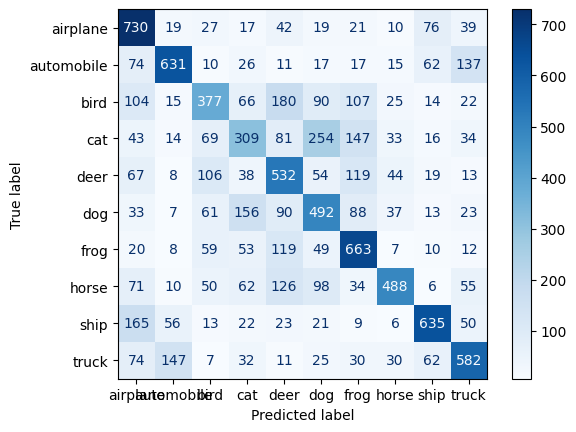

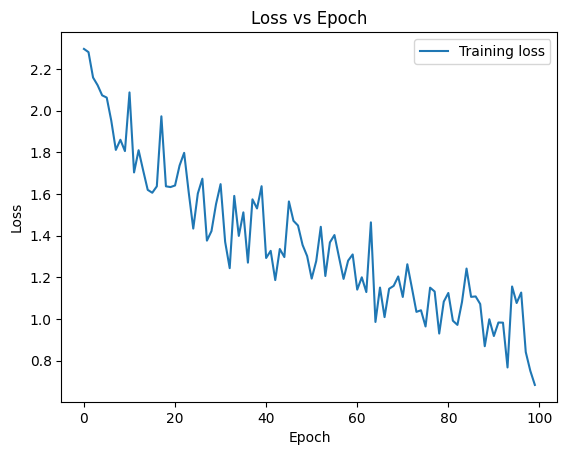

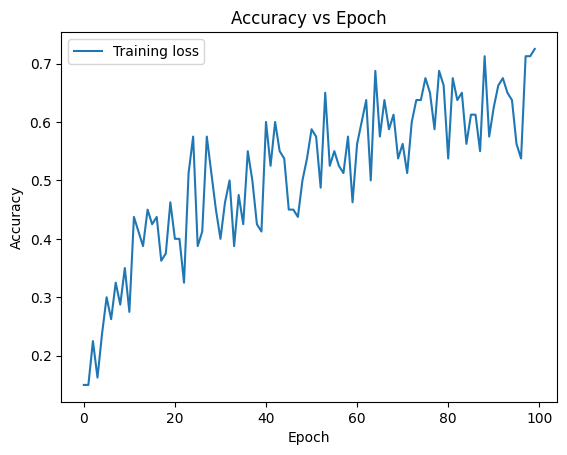

  Epoch    Accuracy      Loss
-------  ----------  --------
      0      0.15    2.29635
      1      0.15    2.2809
      2      0.225   2.15904
      3      0.1625  2.12218
      4      0.2375  2.07338
      5      0.3     2.0628
      6      0.2625  1.9517
      7      0.325   1.81151
      8      0.2875  1.86028
      9      0.35    1.80587
     10      0.275   2.08756
     11      0.4375  1.70338
     12      0.4125  1.81001
     13      0.3875  1.71311
     14      0.45    1.6197
     15      0.425   1.60587
     16      0.4375  1.63658
     17      0.3625  1.97283
     18      0.375   1.63671
     19      0.4625  1.63309
     20      0.4     1.64073
     21      0.4     1.7369
     22      0.325   1.79742
     23      0.5125  1.60811
     24      0.575   1.43383
     25      0.3875  1.60196
     26      0.4125  1.67332
     27      0.575   1.37595
     28      0.5125  1.42176
     29      0.45    1.55141
     30      0.4     1.64708
     31      0.4625  1.37023
     32      0.5 

In [3]:
import sys
import sympy
import sympy.logic
import sympy.logic.boolalg
# Forcefully bind the module into sympy namespace to bypass lazy loading issues
setattr(sympy, 'logic', sys.modules['sympy.logic'])
setattr(sympy, 'core', sys.modules['sympy.core'])

from torch.nn.modules.activation import LogSoftmax
import torch as pt
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import torch.nn as nn
from sklearn.metrics import ConfusionMatrixDisplay
import torchvision
import torchvision.transforms as transforms
from torchvision import datasets
import time
from sklearn.metrics import precision_score, recall_score
from tabulate import tabulate

cifar10 = torchvision.datasets.CIFAR10(root='./data', download=True)
cifar10_val = torchvision.datasets.CIFAR10(root='./data', train=False, download=True)


cifar_i = []
cifar_i_val = []
labels = []
labels_val = []
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


def getaccuracy(predict, y):
  c = 0
  for i in range(len(predict)):
    if abs(predict[i]-y[i]) <= 0.5:
      c += 1
  return c/len(predict)
def getf1(precision, recall):
  return 2*precision*recall/(precision+recall)

for i in range(len(cifar10)):
  img = pt.from_numpy(cifar10.data[i])
  img = img.permute(2,0,1)
  cifar_i.append(img)
  labels.append(cifar10.targets[i])

for i in range(len(cifar10_val)):
  img = pt.from_numpy(cifar10_val.data[i])
  img = img.permute(2,0,1)
  cifar_i_val.append(img)
  labels_val.append(cifar10_val.targets[i])


labels_orig = pt.tensor(labels.copy())

def softmax(x):
  return pt.exp(x) /pt.exp(x).sum()

cifar_i = pt.from_numpy(np.array(cifar_i)).to(pt.float32)/255
cifar_i_val = pt.from_numpy(np.array(cifar_i_val)).to(pt.float32)/255

cifar = pt.utils.data.TensorDataset(cifar_i, pt.from_numpy(np.array(labels)).to(pt.long))
cifar_val = pt.utils.data.TensorDataset(cifar_i_val, pt.from_numpy(np.array(labels_val)).to(pt.long))

train_loader = pt.utils.data.DataLoader(cifar, batch_size=128, shuffle=True)

model = nn.Sequential(
    nn.Linear(3072, 256),
    nn.ReLU(),
    nn.Linear(256, 128),
    nn.ReLU(),
    nn.Linear(128, 256),
    nn.ReLU(),
    nn.Linear(256, 128),
    nn.ReLU(),
    nn.Linear(128, 10),
    nn.LogSoftmax(dim=1)
)
loss_fn = nn.NLLLoss()
optimizer = pt.optim.SGD(model.parameters(), lr=0.01)
n_epochs = 100

start_time = time.perf_counter()
accuracy_over_time = []
loss_over_time = []

for epoch in range(n_epochs):
  for imgs, labels in train_loader:
    batch_size = imgs.shape[0]
    outputs = model(imgs.view(batch_size, -1))
    loss = loss_fn(outputs, labels)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
  loss_over_time.append(loss.detach().tolist())
  accuracy_over_time.append(getaccuracy(pt.argmax(outputs, dim=1), labels))

print("Time: " + str(time.perf_counter() - start_time) + " Seconds")

pred_val = model(cifar_i_val.view(cifar_i_val.shape[0], -1))
pred_val = pt.argmax(pred_val, dim=1)

pred_train = model(cifar_i.view(cifar_i.shape[0], -1))

disp = ConfusionMatrixDisplay.from_predictions(
    np.round(labels_val),
    pred_val.detach().numpy(),
    display_labels=class_names,
    cmap=plt.cm.Blues,
    normalize=None,
)

trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable Parameters: {trainable_params:,}")

print("Training Loss:", loss_fn(pred_train, labels_orig).detach().numpy())
pred_train = pt.argmax(pred_train, dim=1)
print("Training Accuracy", (pred_train == labels_orig).float().mean().item())
print("Validation Accuracy", (pred_val == pt.tensor(labels_val)).float().mean().item())
print("Validation Precision", precision_score(labels_val, pred_val, average="macro"))
print("Validation Recall", recall_score(labels_val, pred_val, average="macro"))
plt.figure()
plt.plot(np.arange(len(loss_over_time)), loss_over_time, label="Training loss")
plt.title("Loss vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()
plt.figure()
plt.plot(np.arange(len(accuracy_over_time)), accuracy_over_time, label="Training loss")
plt.title("Accuracy vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()
tabledata = [np.arange(len(accuracy_over_time)).tolist(), accuracy_over_time, loss_over_time]
tabledata = np.transpose(np.array(tabledata)).tolist()
table = tabulate(tabledata, headers=["Epoch", "Accuracy", "Loss"])
print(table)

Time: 908.5733134339998 Seconds
Trainable Parameters: 2,497,738
Training Loss: 2.3025827
Training Accuracy 0.10000000149011612
Validation Accuracy 0.10000000149011612
Validation Precision 0.01
Validation Recall 0.1


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


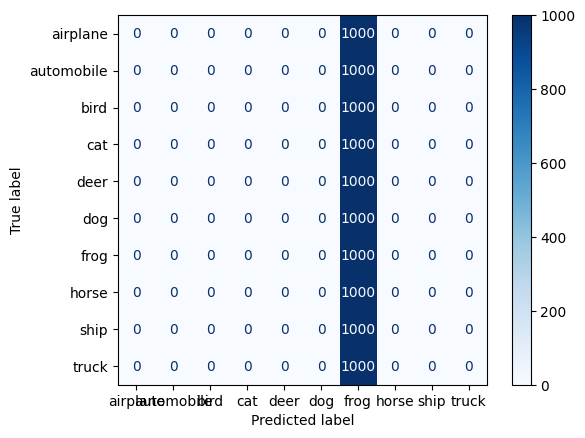

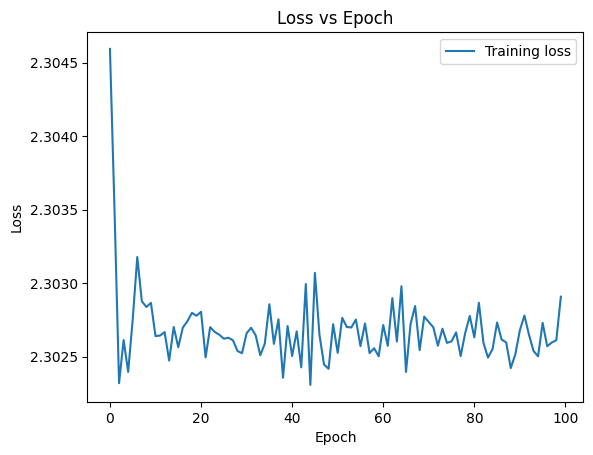

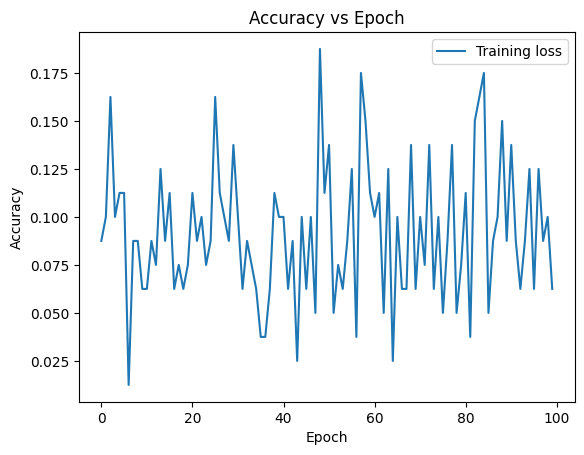

  Epoch    Accuracy     Loss
-------  ----------  -------
      0      0.0875  2.30459
      1      0.1     2.3035
      2      0.1625  2.30232
      3      0.1     2.30261
      4      0.1125  2.3024
      5      0.1125  2.30275
      6      0.0125  2.30318
      7      0.0875  2.30288
      8      0.0875  2.30284
      9      0.0625  2.30287
     10      0.0625  2.30264
     11      0.0875  2.30264
     12      0.075   2.30267
     13      0.125   2.30247
     14      0.0875  2.3027
     15      0.1125  2.30256
     16      0.0625  2.3027
     17      0.075   2.30274
     18      0.0625  2.3028
     19      0.075   2.30278
     20      0.1125  2.3028
     21      0.0875  2.3025
     22      0.1     2.3027
     23      0.075   2.30267
     24      0.0875  2.30265
     25      0.1625  2.30262
     26      0.1125  2.30263
     27      0.1     2.30261
     28      0.0875  2.30254
     29      0.1375  2.30252
     30      0.1     2.30266
     31      0.0625  2.3027
     32      0.0875  2.

In [4]:
import sys
import sympy
import sympy.logic
import sympy.logic.boolalg
# Forcefully bind the module into sympy namespace to bypass lazy loading issues
setattr(sympy, 'logic', sys.modules['sympy.logic'])
setattr(sympy, 'core', sys.modules['sympy.core'])

from torch.nn.modules.activation import LogSoftmax
import torch as pt
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import torch.nn as nn
from sklearn.metrics import ConfusionMatrixDisplay
import torchvision
import torchvision.transforms as transforms
from torchvision import datasets
import time
from sklearn.metrics import precision_score, recall_score
from tabulate import tabulate

cifar10 = torchvision.datasets.CIFAR10(root='./data', download=True)
cifar10_val = torchvision.datasets.CIFAR10(root='./data', train=False, download=True)


cifar_i = []
cifar_i_val = []
labels = []
labels_val = []
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


def getaccuracy(predict, y):
  c = 0
  for i in range(len(predict)):
    if abs(predict[i]-y[i]) <= 0.5:
      c += 1
  return c/len(predict)
def getf1(precision, recall):
  return 2*precision*recall/(precision+recall)

for i in range(len(cifar10)):
  img = pt.from_numpy(cifar10.data[i])
  img = img.permute(2,0,1)
  cifar_i.append(img)
  labels.append(cifar10.targets[i])

for i in range(len(cifar10_val)):
  img = pt.from_numpy(cifar10_val.data[i])
  img = img.permute(2,0,1)
  cifar_i_val.append(img)
  labels_val.append(cifar10_val.targets[i])


labels_orig = pt.tensor(labels.copy())

def softmax(x):
  return pt.exp(x) /pt.exp(x).sum()

cifar_i = pt.from_numpy(np.array(cifar_i)).to(pt.float32)/255
cifar_i_val = pt.from_numpy(np.array(cifar_i_val)).to(pt.float32)/255

cifar = pt.utils.data.TensorDataset(cifar_i, pt.from_numpy(np.array(labels)).to(pt.long))
cifar_val = pt.utils.data.TensorDataset(cifar_i_val, pt.from_numpy(np.array(labels_val)).to(pt.long))

train_loader = pt.utils.data.DataLoader(cifar, batch_size=128, shuffle=True)

model = nn.Sequential(
    nn.Linear(3072, 512),
    nn.ReLU(),
    nn.Linear(512, 128),
    nn.ReLU(),
    nn.Linear(128, 256),
    nn.ReLU(),
    nn.Linear(256, 384),
    nn.ReLU(),
    nn.Linear(384, 512),
    nn.ReLU(),
    nn.Linear(512, 256),
    nn.ReLU(),
    nn.Linear(256, 192),
    nn.ReLU(),
    nn.Linear(192, 256),
    nn.ReLU(),
    nn.Linear(256, 384),
    nn.ReLU(),
    nn.Linear(384, 256),
    nn.ReLU(),
    nn.Linear(256, 384),
    nn.ReLU(),
    nn.Linear(384, 10),
    nn.LogSoftmax(dim=1)
)
loss_fn = nn.NLLLoss()
optimizer = pt.optim.SGD(model.parameters(), lr=0.01)
n_epochs = 100

start_time = time.perf_counter()
accuracy_over_time = []
loss_over_time = []

for epoch in range(n_epochs):
  for imgs, labels in train_loader:
    batch_size = imgs.shape[0]
    outputs = model(imgs.view(batch_size, -1))
    loss = loss_fn(outputs, labels)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
  loss_over_time.append(loss.detach().tolist())
  accuracy_over_time.append(getaccuracy(pt.argmax(outputs, dim=1), labels))

print("Time: " + str(time.perf_counter() - start_time) + " Seconds")

pred_val = model(cifar_i_val.view(cifar_i_val.shape[0], -1))
pred_val = pt.argmax(pred_val, dim=1)

pred_train = model(cifar_i.view(cifar_i.shape[0], -1))

disp = ConfusionMatrixDisplay.from_predictions(
    np.round(labels_val),
    pred_val.detach().numpy(),
    display_labels=class_names,
    cmap=plt.cm.Blues,
    normalize=None,
)

trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable Parameters: {trainable_params:,}")

print("Training Loss:", loss_fn(pred_train, labels_orig).detach().numpy())
pred_train = pt.argmax(pred_train, dim=1)
print("Training Accuracy", (pred_train == labels_orig).float().mean().item())
print("Validation Accuracy", (pred_val == pt.tensor(labels_val)).float().mean().item())
print("Validation Precision", precision_score(labels_val, pred_val, average="macro"))
print("Validation Recall", recall_score(labels_val, pred_val, average="macro"))
plt.figure()
plt.plot(np.arange(len(loss_over_time)), loss_over_time, label="Training loss")
plt.title("Loss vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()
plt.figure()
plt.plot(np.arange(len(accuracy_over_time)), accuracy_over_time, label="Training loss")
plt.title("Accuracy vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()
tabledata = [np.arange(len(accuracy_over_time)).tolist(), accuracy_over_time, loss_over_time]
tabledata = np.transpose(np.array(tabledata)).tolist()
table = tabulate(tabledata, headers=["Epoch", "Accuracy", "Loss"])
print(table)

# Different Activation Functions

Time: 289.57979977099967 Seconds
Trainable Parameters: 820,874
Training Loss: 1.7240607
Training Accuracy 0.38312000036239624
Validation Accuracy 0.3824000060558319
Validation Precision 0.3752851129243524
Validation Recall 0.38239999999999996


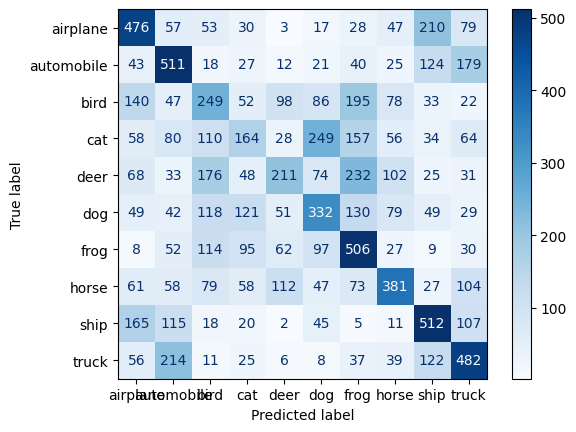

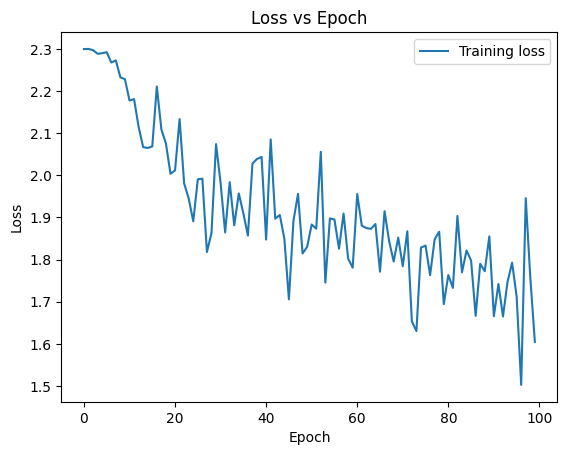

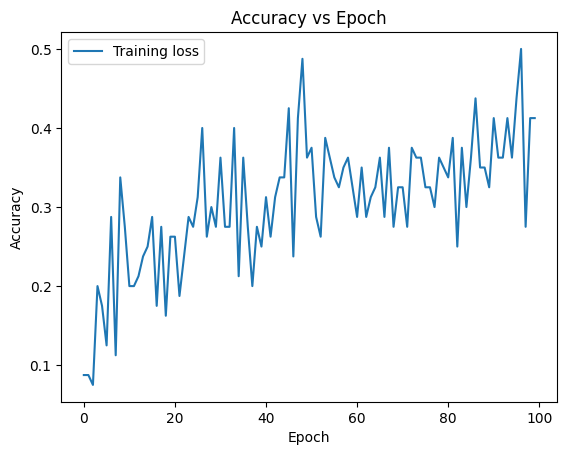

  Epoch    Accuracy     Loss
-------  ----------  -------
      0      0.0875  2.29979
      1      0.0875  2.30015
      2      0.075   2.29726
      3      0.2     2.28861
      4      0.175   2.29
      5      0.125   2.29241
      6      0.2875  2.26785
      7      0.1125  2.27285
      8      0.3375  2.23256
      9      0.275   2.2284
     10      0.2     2.17766
     11      0.2     2.18101
     12      0.2125  2.1152
     13      0.2375  2.067
     14      0.25    2.06498
     15      0.2875  2.06846
     16      0.175   2.21098
     17      0.275   2.109
     18      0.1625  2.07551
     19      0.2625  2.00378
     20      0.2625  2.01182
     21      0.1875  2.13357
     22      0.2375  1.98065
     23      0.2875  1.94478
     24      0.275   1.89087
     25      0.3125  1.99059
     26      0.4     1.99206
     27      0.2625  1.81787
     28      0.3     1.86305
     29      0.275   2.07423
     30      0.3625  1.98212
     31      0.275   1.86437
     32      0.275   1.

In [5]:
import sys
import sympy
import sympy.logic
import sympy.logic.boolalg
# Forcefully bind the module into sympy namespace to bypass lazy loading issues
setattr(sympy, 'logic', sys.modules['sympy.logic'])
setattr(sympy, 'core', sys.modules['sympy.core'])

from torch.nn.modules.activation import LogSoftmax
import torch as pt
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import torch.nn as nn
from sklearn.metrics import ConfusionMatrixDisplay
import torchvision
import torchvision.transforms as transforms
from torchvision import datasets
import time
from sklearn.metrics import precision_score, recall_score
from tabulate import tabulate

cifar10 = torchvision.datasets.CIFAR10(root='./data', download=True)
cifar10_val = torchvision.datasets.CIFAR10(root='./data', train=False, download=True)


cifar_i = []
cifar_i_val = []
labels = []
labels_val = []
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


def getaccuracy(predict, y):
  c = 0
  for i in range(len(predict)):
    if abs(predict[i]-y[i]) <= 0.5:
      c += 1
  return c/len(predict)
def getf1(precision, recall):
  return 2*precision*recall/(precision+recall)

for i in range(len(cifar10)):
  img = pt.from_numpy(cifar10.data[i])
  img = img.permute(2,0,1)
  cifar_i.append(img)
  labels.append(cifar10.targets[i])

for i in range(len(cifar10_val)):
  img = pt.from_numpy(cifar10_val.data[i])
  img = img.permute(2,0,1)
  cifar_i_val.append(img)
  labels_val.append(cifar10_val.targets[i])


labels_orig = pt.tensor(labels.copy())

def softmax(x):
  return pt.exp(x) /pt.exp(x).sum()

cifar_i = pt.from_numpy(np.array(cifar_i)).to(pt.float32)/255
cifar_i_val = pt.from_numpy(np.array(cifar_i_val)).to(pt.float32)/255

cifar = pt.utils.data.TensorDataset(cifar_i, pt.from_numpy(np.array(labels)).to(pt.long))
cifar_val = pt.utils.data.TensorDataset(cifar_i_val, pt.from_numpy(np.array(labels_val)).to(pt.long))

train_loader = pt.utils.data.DataLoader(cifar, batch_size=128, shuffle=True)

model = nn.Sequential(
    nn.Linear(3072, 256),
    nn.Sigmoid(),
    nn.Linear(256, 128),
    nn.Sigmoid(),
    nn.Linear(128, 10),
    nn.LogSoftmax(dim=1)
)
loss_fn = nn.NLLLoss()
optimizer = pt.optim.SGD(model.parameters(), lr=0.01)
n_epochs = 100

start_time = time.perf_counter()
accuracy_over_time = []
loss_over_time = []

for epoch in range(n_epochs):
  for imgs, labels in train_loader:
    batch_size = imgs.shape[0]
    outputs = model(imgs.view(batch_size, -1))
    loss = loss_fn(outputs, labels)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
  loss_over_time.append(loss.detach().tolist())
  accuracy_over_time.append(getaccuracy(pt.argmax(outputs, dim=1), labels))

print("Time: " + str(time.perf_counter() - start_time) + " Seconds")

pred_val = model(cifar_i_val.view(cifar_i_val.shape[0], -1))
pred_val = pt.argmax(pred_val, dim=1)

pred_train = model(cifar_i.view(cifar_i.shape[0], -1))

disp = ConfusionMatrixDisplay.from_predictions(
    np.round(labels_val),
    pred_val.detach().numpy(),
    display_labels=class_names,
    cmap=plt.cm.Blues,
    normalize=None,
)

trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable Parameters: {trainable_params:,}")

print("Training Loss:", loss_fn(pred_train, labels_orig).detach().numpy())
pred_train = pt.argmax(pred_train, dim=1)
print("Training Accuracy", (pred_train == labels_orig).float().mean().item())
print("Validation Accuracy", (pred_val == pt.tensor(labels_val)).float().mean().item())
print("Validation Precision", precision_score(labels_val, pred_val, average="macro"))
print("Validation Recall", recall_score(labels_val, pred_val, average="macro"))
plt.figure()
plt.plot(np.arange(len(loss_over_time)), loss_over_time, label="Training loss")
plt.title("Loss vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()
plt.figure()
plt.plot(np.arange(len(accuracy_over_time)), accuracy_over_time, label="Training loss")
plt.title("Accuracy vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()
tabledata = [np.arange(len(accuracy_over_time)).tolist(), accuracy_over_time, loss_over_time]
tabledata = np.transpose(np.array(tabledata)).tolist()
table = tabulate(tabledata, headers=["Epoch", "Accuracy", "Loss"])
print(table)


Time: 300.9553744349996 Seconds
Trainable Parameters: 820,874
Training Loss: 1.1543018
Training Accuracy 0.5835800170898438
Validation Accuracy 0.5023999810218811
Validation Precision 0.5332440539922627
Validation Recall 0.5024


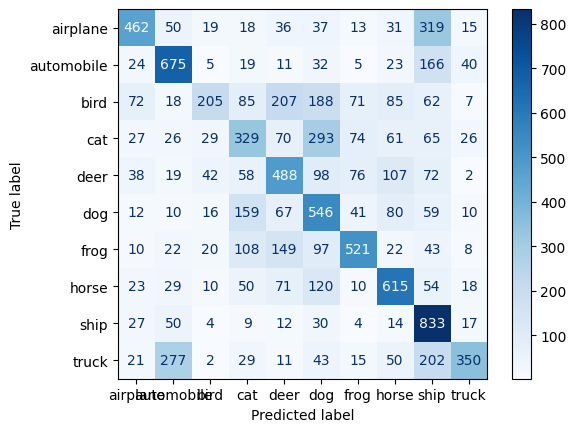

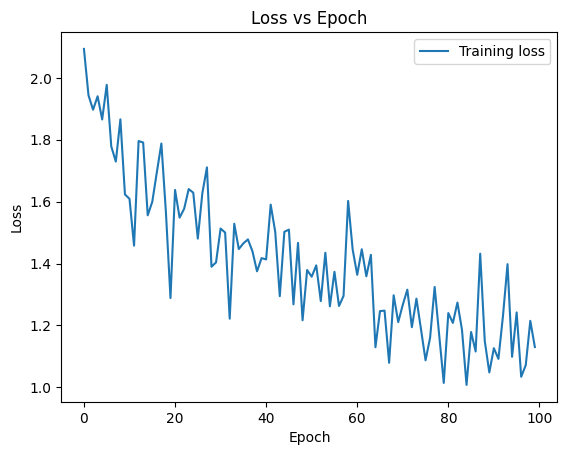

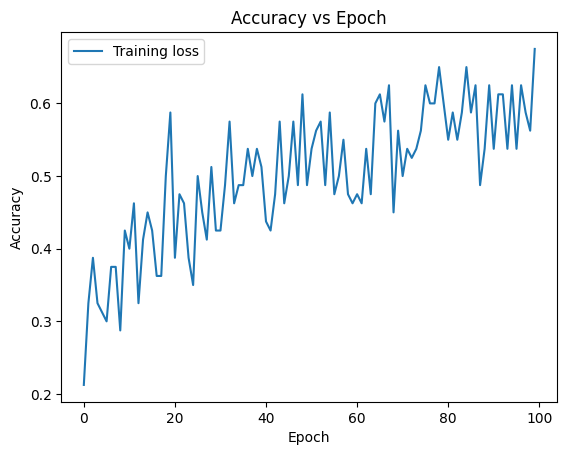

  Epoch    Accuracy     Loss
-------  ----------  -------
      0      0.2125  2.09351
      1      0.325   1.94361
      2      0.3875  1.89698
      3      0.325   1.94057
      4      0.3125  1.86564
      5      0.3     1.97747
      6      0.375   1.77835
      7      0.375   1.72952
      8      0.2875  1.86602
      9      0.425   1.62337
     10      0.4     1.60911
     11      0.4625  1.45781
     12      0.325   1.79594
     13      0.4125  1.791
     14      0.45    1.55592
     15      0.425   1.59944
     16      0.3625  1.69481
     17      0.3625  1.78789
     18      0.5     1.5647
     19      0.5875  1.28858
     20      0.3875  1.63785
     21      0.475   1.54839
     22      0.4625  1.57708
     23      0.3875  1.64061
     24      0.35    1.62903
     25      0.5     1.48067
     26      0.45    1.62787
     27      0.4125  1.71075
     28      0.5125  1.38976
     29      0.425   1.40383
     30      0.425   1.51309
     31      0.4875  1.50018
     32      0.57

In [6]:
import sys
import sympy
import sympy.logic
import sympy.logic.boolalg
# Forcefully bind the module into sympy namespace to bypass lazy loading issues
setattr(sympy, 'logic', sys.modules['sympy.logic'])
setattr(sympy, 'core', sys.modules['sympy.core'])

from torch.nn.modules.activation import LogSoftmax
import torch as pt
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import torch.nn as nn
from sklearn.metrics import ConfusionMatrixDisplay
import torchvision
import torchvision.transforms as transforms
from torchvision import datasets
import time
from sklearn.metrics import precision_score, recall_score
from tabulate import tabulate

cifar10 = torchvision.datasets.CIFAR10(root='./data', download=True)
cifar10_val = torchvision.datasets.CIFAR10(root='./data', train=False, download=True)


cifar_i = []
cifar_i_val = []
labels = []
labels_val = []
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


def getaccuracy(predict, y):
  c = 0
  for i in range(len(predict)):
    if abs(predict[i]-y[i]) <= 0.5:
      c += 1
  return c/len(predict)
def getf1(precision, recall):
  return 2*precision*recall/(precision+recall)

for i in range(len(cifar10)):
  img = pt.from_numpy(cifar10.data[i])
  img = img.permute(2,0,1)
  cifar_i.append(img)
  labels.append(cifar10.targets[i])

for i in range(len(cifar10_val)):
  img = pt.from_numpy(cifar10_val.data[i])
  img = img.permute(2,0,1)
  cifar_i_val.append(img)
  labels_val.append(cifar10_val.targets[i])


labels_orig = pt.tensor(labels.copy())

def softmax(x):
  return pt.exp(x) /pt.exp(x).sum()

cifar_i = pt.from_numpy(np.array(cifar_i)).to(pt.float32)/255
cifar_i_val = pt.from_numpy(np.array(cifar_i_val)).to(pt.float32)/255

cifar = pt.utils.data.TensorDataset(cifar_i, pt.from_numpy(np.array(labels)).to(pt.long))
cifar_val = pt.utils.data.TensorDataset(cifar_i_val, pt.from_numpy(np.array(labels_val)).to(pt.long))

train_loader = pt.utils.data.DataLoader(cifar, batch_size=128, shuffle=True)

model = nn.Sequential(
    nn.Linear(3072, 256),
    nn.Tanh(),
    nn.Linear(256, 128),
    nn.Tanh(),
    nn.Linear(128, 10),
    nn.LogSoftmax(dim=1)
)
loss_fn = nn.NLLLoss()
optimizer = pt.optim.SGD(model.parameters(), lr=0.01)
n_epochs = 100

start_time = time.perf_counter()
accuracy_over_time = []
loss_over_time = []

for epoch in range(n_epochs):
  for imgs, labels in train_loader:
    batch_size = imgs.shape[0]
    outputs = model(imgs.view(batch_size, -1))
    loss = loss_fn(outputs, labels)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
  loss_over_time.append(loss.detach().tolist())
  accuracy_over_time.append(getaccuracy(pt.argmax(outputs, dim=1), labels))

print("Time: " + str(time.perf_counter() - start_time) + " Seconds")

pred_val = model(cifar_i_val.view(cifar_i_val.shape[0], -1))
pred_val = pt.argmax(pred_val, dim=1)

pred_train = model(cifar_i.view(cifar_i.shape[0], -1))

disp = ConfusionMatrixDisplay.from_predictions(
    np.round(labels_val),
    pred_val.detach().numpy(),
    display_labels=class_names,
    cmap=plt.cm.Blues,
    normalize=None,
)

trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable Parameters: {trainable_params:,}")

print("Training Loss:", loss_fn(pred_train, labels_orig).detach().numpy())
pred_train = pt.argmax(pred_train, dim=1)
print("Training Accuracy", (pred_train == labels_orig).float().mean().item())
print("Validation Accuracy", (pred_val == pt.tensor(labels_val)).float().mean().item())
print("Validation Precision", precision_score(labels_val, pred_val, average="macro"))
print("Validation Recall", recall_score(labels_val, pred_val, average="macro"))
plt.figure()
plt.plot(np.arange(len(loss_over_time)), loss_over_time, label="Training loss")
plt.title("Loss vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()
plt.figure()
plt.plot(np.arange(len(accuracy_over_time)), accuracy_over_time, label="Training loss")
plt.title("Accuracy vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()
tabledata = [np.arange(len(accuracy_over_time)).tolist(), accuracy_over_time, loss_over_time]
tabledata = np.transpose(np.array(tabledata)).tolist()
table = tabulate(tabledata, headers=["Epoch", "Accuracy", "Loss"])
print(table)